In [1]:
import pandas as pd
df = pd.read_csv("../data/Fraud_Data.csv")

In [2]:
print(df.shape)

(151112, 11)


In [ ]:
print(df.columns)

Index(['user_id', 'signup_time', 'purchase_time', 'purchase_value',
       'device_id', 'source', 'browser', 'sex', 'age', 'ip_address', 'class'],
      dtype='str')


In [4]:
print(df.head())

   user_id          signup_time        purchase_time  purchase_value  \
0    22058  2015-02-24 22:55:49  2015-04-18 02:47:11              34   
1   333320  2015-06-07 20:39:50  2015-06-08 01:38:54              16   
2     1359  2015-01-01 18:52:44  2015-01-01 18:52:45              15   
3   150084  2015-04-28 21:13:25  2015-05-04 13:54:50              44   
4   221365  2015-07-21 07:09:52  2015-09-09 18:40:53              39   

       device_id source browser sex  age    ip_address  class  
0  QVPSPJUOCKZAR    SEO  Chrome   M   39  7.327584e+08      0  
1  EOGFQPIZPYXFZ    Ads  Chrome   F   53  3.503114e+08      0  
2  YSSKYOSJHPPLJ    SEO   Opera   M   53  2.621474e+09      1  
3  ATGTXKYKUDUQN    SEO  Safari   M   41  3.840542e+09      0  
4  NAUITBZFJKHWW    Ads  Safari   M   45  4.155831e+08      0  


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 151112 entries, 0 to 151111
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   user_id         151112 non-null  int64  
 1   signup_time     151112 non-null  str    
 2   purchase_time   151112 non-null  str    
 3   purchase_value  151112 non-null  int64  
 4   device_id       151112 non-null  str    
 5   source          151112 non-null  str    
 6   browser         151112 non-null  str    
 7   sex             151112 non-null  str    
 8   age             151112 non-null  int64  
 9   ip_address      151112 non-null  float64
 10  class           151112 non-null  int64  
dtypes: float64(1), int64(4), str(6)
memory usage: 12.7 MB


In [6]:
print(df.isnull().sum())

user_id           0
signup_time       0
purchase_time     0
purchase_value    0
device_id         0
source            0
browser           0
sex               0
age               0
ip_address        0
class             0
dtype: int64


In [7]:
print(df.duplicated().sum())

0


In [8]:
print(df['class'].value_counts())

class
0    136961
1     14151
Name: count, dtype: int64


In [9]:
print(df['class'].value_counts(normalize=True) * 100)

class
0    90.635423
1     9.364577
Name: proportion, dtype: float64


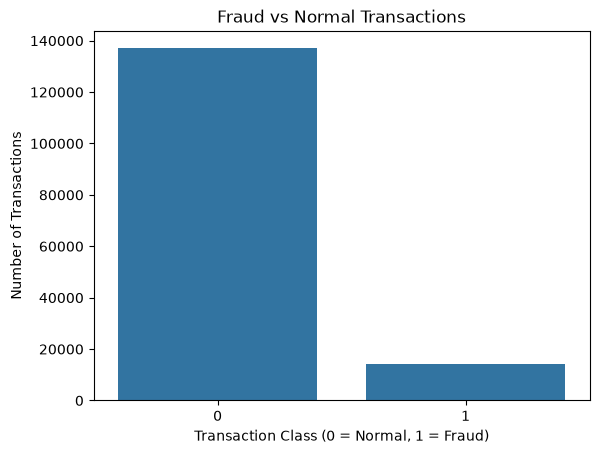

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='class', data=df)

plt.title('Fraud vs Normal Transactions')
plt.xlabel('Transaction Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()

In [26]:
print("Unique users:", df['user_id'].nunique())
print("Unique devices:", df['device_id'].nunique())
print("Unique browsers:", df['browser'].nunique())
print("Unique sources:", df['source'].nunique())

Unique users: 151112
Unique devices: 137956
Unique browsers: 5
Unique sources: 3


In [12]:
#Checking if fraudulent purchases are generally more expensive:
print(df.groupby('class')['purchase_value'].describe())

          count       mean        std  min   25%   50%   75%    max
class                                                              
0      136961.0  36.929418  18.315064  9.0  22.0  35.0  49.0  154.0
1       14151.0  36.993004  18.397654  9.0  22.0  35.0  49.0  111.0


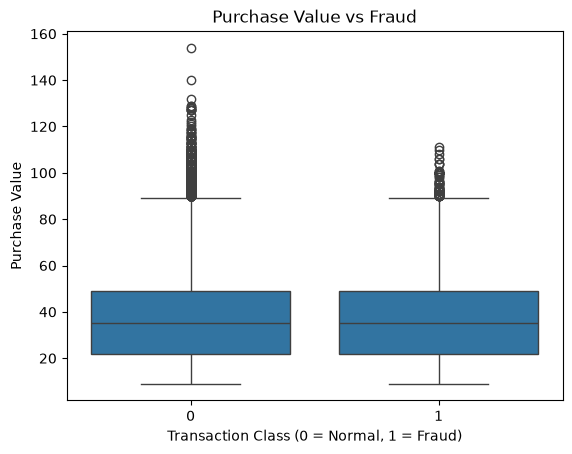

In [13]:
sns.boxplot(x='class', y='purchase_value', data=df)

plt.title('Purchase Value vs Fraud')
plt.xlabel('Transaction Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Purchase Value')

plt.show()

In [ ]:
#Checking if fraudulent purchases are generally made by new users:
df['signup_time'] = pd.to_datetime(df['signup_time'])
df['purchase_time'] = pd.to_datetime(df['purchase_time'])

In [23]:
df['account_age'] = (df['purchase_time'] - df['signup_time']).dt.total_seconds() / 3600
print(df[['signup_time', 'purchase_time', 'account_age', 'class']].head())

          signup_time       purchase_time  account_age  class
0 2015-02-24 22:55:49 2015-04-18 02:47:11  1251.856111      0
1 2015-06-07 20:39:50 2015-06-08 01:38:54     4.984444      0
2 2015-01-01 18:52:44 2015-01-01 18:52:45     0.000278      1
3 2015-04-28 21:13:25 2015-05-04 13:54:50   136.690278      0
4 2015-07-21 07:09:52 2015-09-09 18:40:53  1211.516944      0


In [18]:
print(df.groupby('class')['account_age'].describe())

          count         mean         std       min         25%          50%  \
class                                                                         
0      136961.0  1441.994052  830.163558  0.038056  719.119167  1443.030833   
1       14151.0   673.289542  920.496897  0.000278    0.000278     0.000278   

               75%          max  
class                            
0      2161.477500  2879.992222  
1      1330.697361  2878.874167  


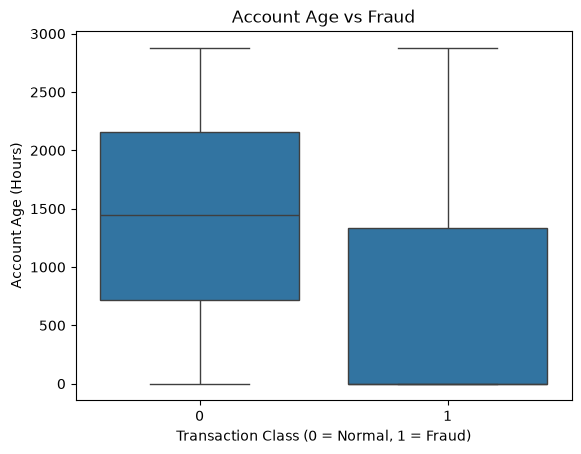

In [19]:
sns.boxplot(x='class', y='account_age', data=df)

plt.title('Account Age vs Fraud')
plt.xlabel('Transaction Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Account Age (Hours)')

plt.show()

In [25]:
#Checking if fraudulent purchases are generally made from specific browsers or traffic sources:
print(df.groupby('browser')['class'].mean() * 100)
print('\n',df.groupby('source')['class'].mean() * 100)

browser
Chrome     9.879216
FireFox    9.516457
IE         8.677540
Opera      8.922742
Safari     9.020148
Name: class, dtype: float64

 source
Ads        9.206593
Direct    10.536974
SEO        8.928483
Name: class, dtype: float64


In [30]:
#Checking if multiple users are using the same device:
device_counts = df['device_id'].value_counts()
shared_devices = device_counts[device_counts > 1]
print("Total unique devices:", df['device_id'].nunique())
print("Shared devices:", len(shared_devices))

Total unique devices: 137956
Shared devices: 6175


In [31]:
device_counts = df['device_id'].value_counts()
df['device_count'] = df['device_id'].map(device_counts)
df['shared_device'] = df['device_count'] > 1
print(df['shared_device'].value_counts())

shared_device
False    131781
True      19331
Name: count, dtype: int64


In [28]:
print(df.groupby('shared_device')['class'].mean() * 100)

shared_device
False     3.042927
True     52.459780
Name: class, dtype: float64


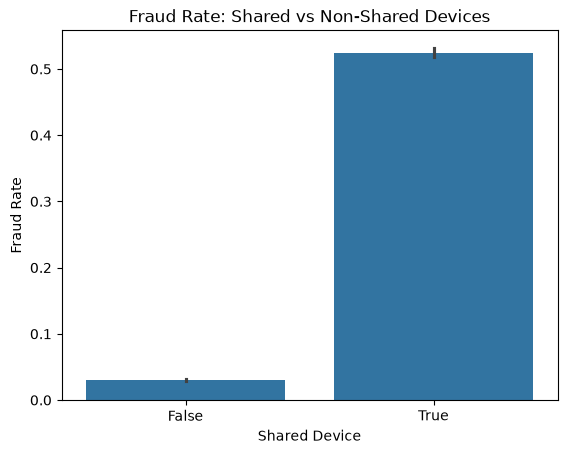

In [29]:
sns.barplot(x='shared_device', y='class', data=df)

plt.title('Fraud Rate: Shared vs Non-Shared Devices')
plt.xlabel('Shared Device')
plt.ylabel('Fraud Rate')

plt.show()

In [32]:
device_analysis = df.groupby('shared_device')['class'].agg(['count', 'sum', 'mean'])

device_analysis['fraud_percentage'] = device_analysis['mean'] * 100
print(device_analysis)

                count    sum      mean  fraud_percentage
shared_device                                           
False          131781   4010  0.030429          3.042927
True            19331  10141  0.524598         52.459780


In [35]:
print(df['ip_address'].describe())

count    1.511120e+05
mean     2.152145e+09
std      1.248497e+09
min      5.209350e+04
25%      1.085934e+09
50%      2.154770e+09
75%      3.243258e+09
max      4.294850e+09
Name: ip_address, dtype: float64


In [36]:
ip_df = pd.read_csv("../data/IpAddress_to_Country.csv")

In [37]:
print(ip_df.shape)

(138846, 3)


In [38]:
print(ip_df.columns)

Index(['lower_bound_ip_address', 'upper_bound_ip_address', 'country'],
      dtype='str')


In [39]:
print(ip_df.head())

   lower_bound_ip_address  upper_bound_ip_address    country
0              16777216.0                16777471  Australia
1              16777472.0                16777727      China
2              16777728.0                16778239      China
3              16778240.0                16779263  Australia
4              16779264.0                16781311      China


In [41]:
print(ip_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 138846 entries, 0 to 138845
Data columns (total 3 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   lower_bound_ip_address  138846 non-null  float64
 1   upper_bound_ip_address  138846 non-null  int64  
 2   country                 138846 non-null  str    
dtypes: float64(1), int64(1), str(1)
memory usage: 3.2 MB
None


In [42]:
print(ip_df.isnull().sum())

lower_bound_ip_address    0
upper_bound_ip_address    0
country                   0
dtype: int64


In [43]:
ip_df = ip_df.sort_values('lower_bound_ip_address').reset_index(drop=True)

In [44]:
import numpy as np

ip_values = df['ip_address'].values

lower_bounds = ip_df['lower_bound_ip_address'].values
upper_bounds = ip_df['upper_bound_ip_address'].values
countries = ip_df['country'].values

indices = np.searchsorted(lower_bounds, ip_values, side='right') - 1

df['country'] = np.where(
    (indices >= 0) &
    (ip_values <= upper_bounds[np.maximum(indices, 0)]),
    countries[np.maximum(indices, 0)],
    'Unknown'
)

In [45]:
print(df[['ip_address', 'country']].head(10))

     ip_address        country
0  7.327584e+08          Japan
1  3.503114e+08  United States
2  2.621474e+09  United States
3  3.840542e+09        Unknown
4  4.155831e+08  United States
5  2.809315e+09         Canada
6  3.987484e+09        Unknown
7  1.692459e+09  United States
8  3.719094e+09          China
9  3.416747e+08  United States


In [46]:
print(df['country'].value_counts().head(15))

country
United States         58049
Unknown               21966
China                 12038
Japan                  7306
United Kingdom         4490
Korea Republic of      4162
Germany                3646
France                 3161
Canada                 2975
Brazil                 2961
Italy                  1944
Australia              1844
Netherlands            1680
Russian Federation     1616
India                  1310
Name: count, dtype: int64


In [47]:
print("Unknown IP addresses:", (df['country'] == 'Unknown').sum())

Unknown IP addresses: 21966


In [48]:
print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (151112, 15)

Dataset Columns:
['user_id', 'signup_time', 'purchase_time', 'purchase_value', 'device_id', 'source', 'browser', 'sex', 'age', 'ip_address', 'class', 'account_age', 'device_count', 'shared_device', 'country']

Missing Values:
user_id           0
signup_time       0
purchase_time     0
purchase_value    0
device_id         0
source            0
browser           0
sex               0
age               0
ip_address        0
class             0
account_age       0
device_count      0
shared_device     0
country           0
dtype: int64


In [49]:
print(df.dtypes)

user_id                    int64
signup_time       datetime64[us]
purchase_time     datetime64[us]
purchase_value             int64
device_id                    str
source                       str
browser                      str
sex                          str
age                        int64
ip_address               float64
class                      int64
account_age              float64
device_count               int64
shared_device               bool
country                      str
dtype: object


In [51]:
country_analysis = df.groupby('country')['class'].agg(
    total_transactions='count',
    fraud_cases='sum',
    fraud_rate='mean'
)

country_analysis['fraud_rate'] = country_analysis['fraud_rate'] * 100

country_analysis = country_analysis.sort_values(
    by='fraud_rate', ascending=False
)

print(country_analysis.head(15))

                       total_transactions  fraud_cases  fraud_rate
country                                                           
Turkmenistan                            1            1  100.000000
Namibia                                23           10   43.478261
Sri Lanka                              31           13   41.935484
Luxembourg                             72           28   38.888889
Virgin Islands (U.S.)                   3            1   33.333333
Ecuador                               106           28   26.415094
Tunisia                               118           31   26.271186
Peru                                  119           31   26.050420
Bolivia                                53           13   24.528302
Kuwait                                 90           21   23.333333
Ireland                               240           55   22.916667
New Zealand                           278           62   22.302158
Uzbekistan                             10            2   20.00

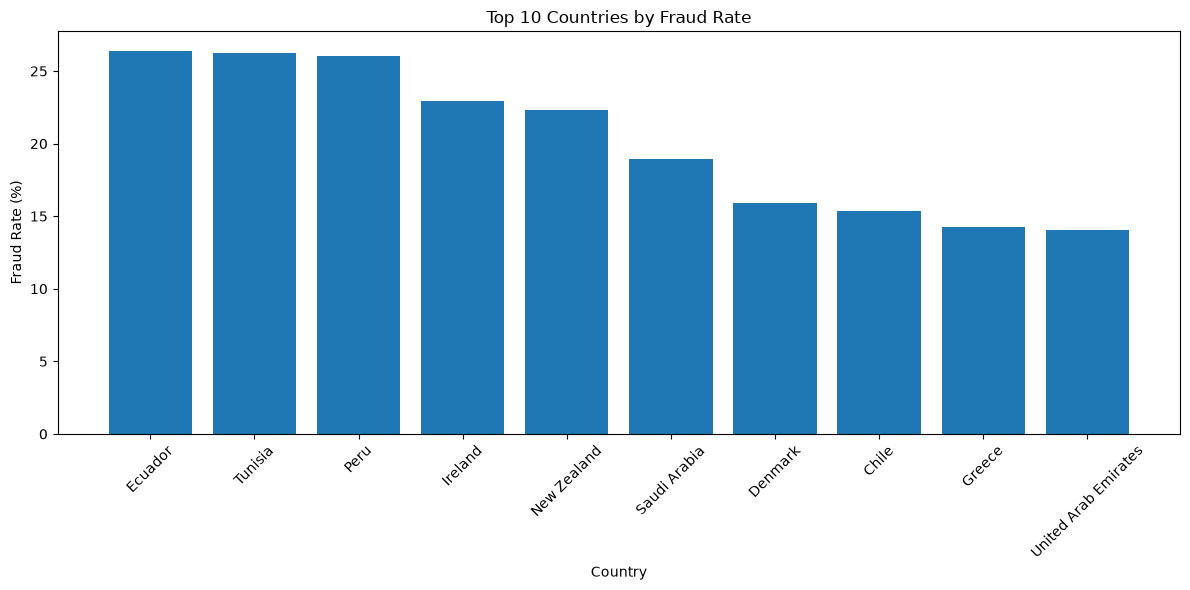

In [52]:
import matplotlib.pyplot as plt

country_filtered = country_analysis[
    country_analysis['total_transactions'] >= 100
]

country_filtered = country_filtered.sort_values(
    by='fraud_rate', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(country_filtered.index, country_filtered['fraud_rate'])

plt.title('Top 10 Countries by Fraud Rate')
plt.xlabel('Country')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
df.to_csv('../data/fraud_data_engineered.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
